# Predicting the Nusselt number in 2D Rayleigh–Bénard convection — comprehensive study

Inputs `Pr`, `Ra` → output `Nu`, for a closed 2D square box (Γ = 1, no-slip walls,
isothermal plates, adiabatic sidewalls). 194 DNS points from 10 papers; full
provenance in `docs/data_sources.pdf`.

**What this notebook does**

1. Pulls the repo from GitHub and loads the data with its provenance.
2. Describes the dataset as a whole: ranges of `Pr`, `Ra`, `Nu`, coverage, cross-source agreement.
3. Makes a **grouped train / validation / test split** and reports the range of every variable in each split, including which test points need extrapolation.
4. Compares 10 regression methods: the paper's random forest, the methods it tried before, and physics-informed / probabilistic alternatives. Hyperparameters are tuned on validation only, and the test set is touched once.
5. Repeated grouped cross-validation, parity and residual plots.
6. **Learning curves**: how much data each method needs.
7. **Active learning curves**: whether choosing which simulation to run next beats random selection.
8. Extrapolation stress tests (hold out a source, high `Ra`, low or high `Pr`).
9. The Gaussian-process response surface `Nu(Pr, Ra)` with its uncertainty.
10. Sensitivity to the flagged (multistable or conflicting) rows.

**Running on Kaggle:** *Settings → Internet → On* (needed for `git clone`), then
*Run All*. CPU is enough; the whole notebook takes about 5–10 minutes. Figures and
tables are written to `/kaggle/working/figures` and `/kaggle/working/tables`, and
zipped at the end.

## 0. Setup — get the repo

In [1]:
import os, subprocess, sys, pathlib

REPO_URL = "https://github.com/manyagupta13/rayleigh-benard"
BRANCH   = "main"          # change if the data update lives on another branch

# Local override (e.g. running on your laptop inside the repo): set RB_REPO_DIR
if os.environ.get("RB_REPO_DIR"):
    REPO = pathlib.Path(os.environ["RB_REPO_DIR"]).resolve()
else:
    base = pathlib.Path("/kaggle/working") if pathlib.Path("/kaggle/working").exists() else pathlib.Path.cwd()
    REPO = base / "rayleigh-benard"
    if not (REPO / ".git").exists():
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO_URL, str(REPO)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=False)

OUT = (pathlib.Path("/kaggle/working") if pathlib.Path("/kaggle/working").exists() else pathlib.Path.cwd())
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
TAB = OUT / "tables";  TAB.mkdir(exist_ok=True)
print("repo:", REPO)
print(subprocess.run(["git", "-C", str(REPO), "log", "-1", "--format=%h %ad %s", "--date=short"],
                     capture_output=True, text=True).stdout)

repo: /home/claude/manyagupta13/rayleigh-benard
84e6fda 2026-09-12 Resize README image with HTML img tags; add Data/Method comparison sections



In [2]:
import warnings, time, itertools
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.spatial import Delaunay

import sklearn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, ConstantKernel as C, WhiteKernel
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
SEED = 42
print("sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# ---- plotting style: recessive axes, thin marks, one validated palette ----
SER = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF, GHOST = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#c9c8c2"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SPLIT_COLOR = {"train": SER[0], "val": SER[1], "test": SER[2]}
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GHOST, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 1.6, "font.size": 10, "axes.titlesize": 11, "axes.titlecolor": INK,
    "legend.frameon": False, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
DOT = dict(s=34, edgecolor=SURF, linewidth=0.7)   # markers with a thin surface ring

sklearn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


## 1. Load the data

`nu_dataset_model.csv` has `Pr, Ra, Nu` only. `nu_dataset_sources.csv` is the same
rows plus `Source`, `Grid`, `Notes` and `Flag`. Rows reporting the same `(Pr, Ra)` from
different papers are kept: they are independent simulations. They share a
**group key**, so a physical point never sits in both train and test.

In [3]:
df = pd.read_csv(REPO / "data" / "nu_dataset_sources.csv", keep_default_na=False)
for c in ["Pr", "Ra", "Nu"]:
    df[c] = df[c].astype(float)
assert len(df) == len(pd.read_csv(REPO / "data" / "nu_dataset_model.csv")), "model/sources files out of sync"
if len(df) < 194:
    print(f"WARNING: only {len(df)} rows — the repo on '{BRANCH}' does not have the expanded dataset yet.")

df["logPr"], df["logRa"], df["logNu"] = np.log10(df.Pr), np.log10(df.Ra), np.log10(df.Nu)
df["group"] = df.Pr.round(4).astype(str) + "|" + df.Ra.map(lambda v: f"{v:.4g}")
df["NuRa03"] = df.Nu / df.Ra ** 0.3

FAMILY = {
    "ShreshthiPandey2026_T1": "Pandey group (spectral element)", "Pandey2021_T1": "Pandey group (spectral element)",
    "PandeyTiwariSreenivasan2026_T1": "Pandey group (spectral element)", "PandeySreenivasan2025_T1": "Pandey group (spectral element)",
    "ZhangZhou2024_T2": "Zhou group (compact FD)", "ZhangZhouSun2017_T1": "Zhou group (compact FD)",
    "vanderPoel2013_T2": "van der Poel group (FD)", "vanderPoel2012_Fig1a_vector": "van der Poel group (FD)",
    "He2021_Fig5a_vector": "He et al. 2021 (FD)", "XuShiXi2019_T2": "Xu et al. 2019 (LBM)",
}
df["Family"] = df.Source.map(FAMILY)
assert df.Family.notna().all()

X_all = df[["logPr", "logRa"]].to_numpy()
y_all = df.Nu.to_numpy()
g_all = df.group.to_numpy()
print(f"{len(df)} rows, {df.group.nunique()} distinct (Pr, Ra) points, {df.Source.nunique()} sources")
df.head()

194 rows, 172 distinct (Pr, Ra) points, 10 sources


,Pr,Ra,Nu,Source,Grid,Notes,Flag,logPr,logRa,logNu,group,NuRa03,Family
0,0.021,1.000000e+09,37.43,ShreshthiPandey2026_T1,,,,-1.677781,9.0,1.573220,0.021|1e+09,0.074683,Pandey group (spectral element)
1,0.050,1.000000e+09,41.51,ShreshthiPandey2026_T1,,,,-1.301030,9.0,1.618153,0.05|1e+09,0.082823,Pandey group (spectral element)
2,0.100,1.000000e+09,42.72,ShreshthiPandey2026_T1,,,,-1.000000,9.0,1.630631,0.1|1e+09,0.085238,Pandey group (spectral element)
3,0.200,1.000000e+09,45.98,ShreshthiPandey2026_T1,,,,-0.698970,9.0,1.662569,0.2|1e+09,0.091742,Pandey group (spectral element)
4,0.350,1.000000e+09,48.10,ShreshthiPandey2026_T1,,,,-0.455932,9.0,1.682145,0.35|1e+09,0.095972,Pandey group (spectral element)


## 2. The dataset as a whole

In [4]:
def ranges(d, label):
    return pd.Series({
        "rows": len(d), "distinct points": d.group.nunique(),
        "Pr min": d.Pr.min(), "Pr max": d.Pr.max(),
        "Ra min": d.Ra.min(), "Ra max": d.Ra.max(),
        "Nu min": d.Nu.min(), "Nu median": d.Nu.median(), "Nu max": d.Nu.max(),
    }, name=label)

overall = ranges(df, "ALL DATA")
by_source = pd.DataFrame([ranges(d, s) for s, d in df.groupby("Source")]).sort_values("rows", ascending=False)
range_table = pd.concat([overall.to_frame().T, by_source])
range_table.to_csv(TAB / "ranges_by_source.csv")
fmt = {c: "{:.3g}" for c in range_table.columns if c not in ("rows", "distinct points")}
fmt.update({"Ra min": "{:.1e}", "Ra max": "{:.1e}"})
range_table.style.format(fmt)

,rows,distinct points,Pr min,Pr max,Ra min,Ra max,Nu min,Nu median,Nu max
ALL DATA,194.000000,172.000000,0.005,100,5.0e+05,1.0e+12,5.2,25.3,394
He2021_Fig5a_vector,62.000000,62.000000,0.25,100,1.0e+07,1.0e+10,11.1,34.2,106
PandeySreenivasan2025_T1,29.000000,29.000000,0.1,1,1.0e+06,1.0e+12,5.91,17.5,394
ZhangZhouSun2017_T1,18.000000,18.000000,0.7,5.3,1.0e+06,1.0e+10,6.3,25.7,103
vanderPoel2012_Fig1a_vector,16.000000,16.000000,1,1,1.0e+07,1.0e+10,8.47,45.9,97
vanderPoel2013_T2,16.000000,16.000000,0.045,55,1.0e+08,1.0e+08,20.5,25.2,27.8
ZhangZhou2024_T2,15.000000,15.000000,0.005,0.15,1.0e+07,1.0e+08,8.91,13,24.2
ShreshthiPandey2026_T1,13.000000,13.000000,0.021,50,1.0e+09,1.0e+09,37.4,49.2,53.4
PandeyTiwariSreenivasan2026_T1,12.000000,12.000000,0.021,0.05,1.0e+07,5.0e+08,11,16.3,33.5
XuShiXi2019_T2,8.000000,8.000000,0.025,0.025,1.0e+06,1.0e+07,6.28,8.13,11.4


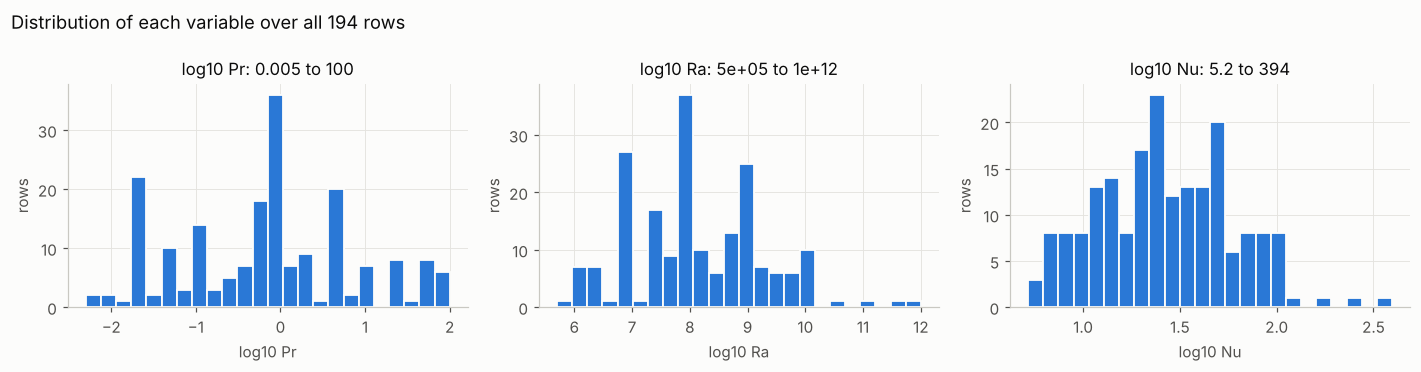

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col, lab in zip(ax, ["logPr", "logRa", "logNu"], ["log10 Pr", "log10 Ra", "log10 Nu"]):
    a.hist(df[col], bins=24, color=SER[0], edgecolor=SURF, linewidth=1.2)
    a.set_xlabel(lab); a.set_ylabel("rows")
    lo, hi = df[col].min(), df[col].max()
    a.set_title(f"{lab}: {10**lo:.3g} to {10**hi:.3g}")
fig.suptitle("Distribution of each variable over all 194 rows", x=0.01, ha="left", color=INK)
fig.tight_layout(); save(fig, "01_histograms")

**Coverage map.** Each panel highlights one code family over the rest (grey), so
you can see which part of the `(Pr, Ra)` plane each group of codes covers.
Marker size grows with `Nu`.

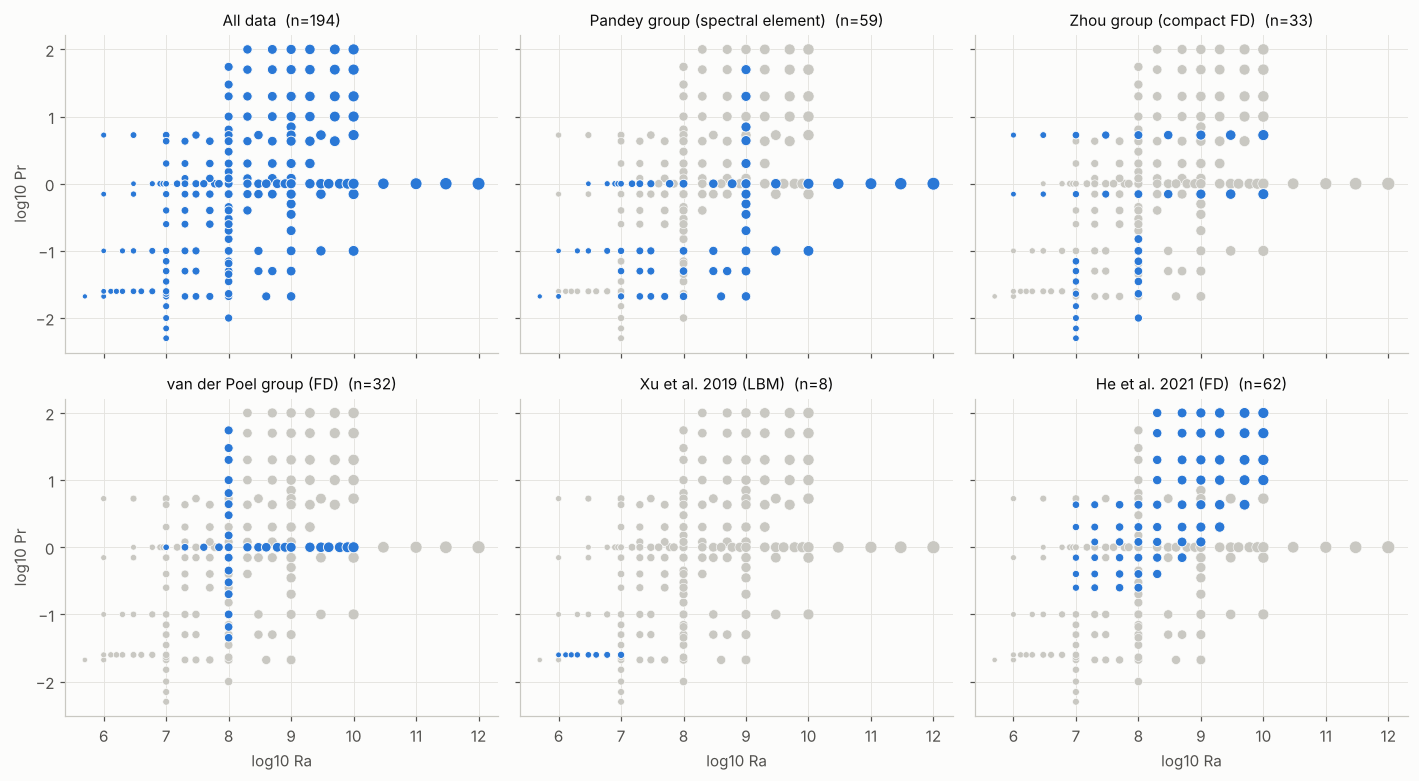

In [6]:
fams = list(dict.fromkeys(df.Family))
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), sharex=True, sharey=True)
for a, fam in zip(axes.flat, ["All data"] + fams):
    sz = 12 + 60 * (df.logNu - df.logNu.min()) / (df.logNu.max() - df.logNu.min())
    if fam == "All data":
        a.scatter(df.logRa, df.logPr, s=sz, c=SER[0], edgecolor=SURF, linewidth=0.6)
    else:
        m = df.Family == fam
        a.scatter(df.logRa[~m], df.logPr[~m], s=sz[~m], c=GHOST, edgecolor=SURF, linewidth=0.4)
        a.scatter(df.logRa[m], df.logPr[m], s=sz[m], c=SER[0], edgecolor=SURF, linewidth=0.6)
    n = len(df) if fam == "All data" else int((df.Family == fam).sum())
    a.set_title(f"{fam}  (n={n})", fontsize=10)
for a in axes[-1]: a.set_xlabel("log10 Ra")
for a in axes[:, 0]: a.set_ylabel("log10 Pr")
fig.tight_layout(); save(fig, "02_coverage_by_family")

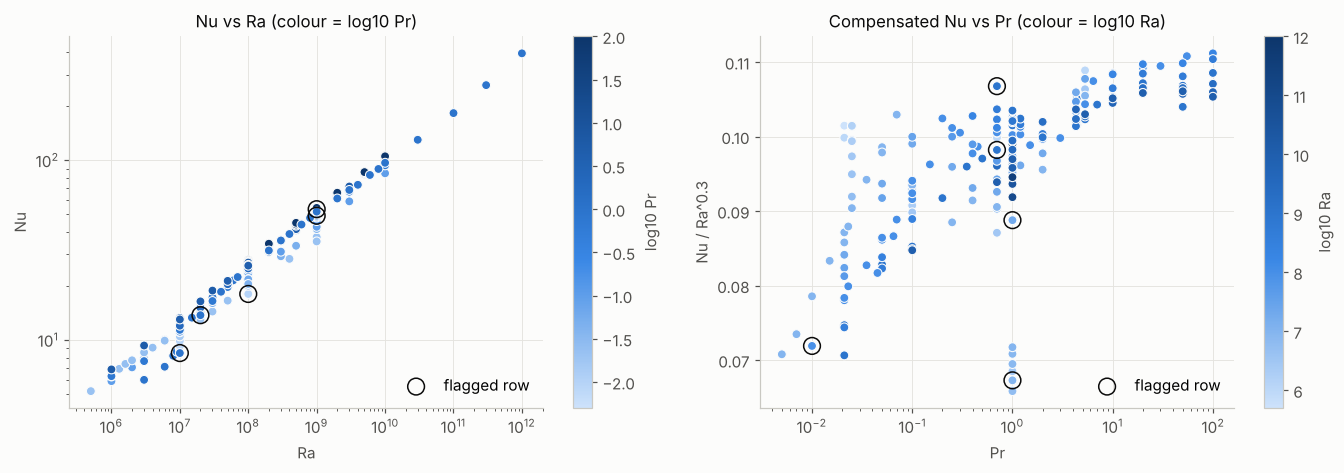

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
sc = ax[0].scatter(df.Ra, df.Nu, c=df.logPr, cmap=BLUES, **DOT)
ax[0].set(xscale="log", yscale="log", xlabel="Ra", ylabel="Nu", title="Nu vs Ra (colour = log10 Pr)")
fig.colorbar(sc, ax=ax[0], label="log10 Pr")
sc = ax[1].scatter(df.Pr, df.NuRa03, c=df.logRa, cmap=BLUES, **DOT)
ax[1].set(xscale="log", xlabel="Pr", ylabel="Nu / Ra^0.3", title="Compensated Nu vs Pr (colour = log10 Ra)")
fig.colorbar(sc, ax=ax[1], label="log10 Ra")
fl = df[df.Flag != ""]
for a, xc, yc in [(ax[0], "Ra", "Nu"), (ax[1], "Pr", "NuRa03")]:
    a.scatter(fl[xc], fl[yc], s=120, facecolor="none", edgecolor=INK, linewidth=1.0, label="flagged row")
    a.legend(loc="lower right")
fig.tight_layout(); save(fig, "03_nu_vs_ra_pr")

The compensated plot is the most informative view. It shows `Nu` rising with
`Pr` at low `Pr`, then flattening, and a visible scatter of about ±5 % at fixed
`(Pr, Ra)` near `Pr ≈ 0.2–3`. That scatter is the 2D roll-state multistability
reported by van der Poel et al. (2012, 2013), and it sets a floor on how accurate
any `(Pr, Ra) → Nu` model can be.

### Cross-source agreement

In [8]:
rep = df.groupby("group").filter(lambda d: d.Source.nunique() > 1)
agree = (rep.groupby("group")
            .agg(Pr=("Pr", "first"), Ra=("Ra", "first"), n=("Nu", "size"),
                 Nu_min=("Nu", "min"), Nu_max=("Nu", "max"),
                 sources=("Source", lambda s: ", ".join(s)))
            .assign(spread_pct=lambda d: 100 * (d.Nu_max - d.Nu_min) / ((d.Nu_max + d.Nu_min) / 2))
            .sort_values("spread_pct"))
agree.to_csv(TAB / "cross_source_agreement.csv")
print(f"{len(agree)} points reported by >1 source; median spread {agree.spread_pct.median():.2f} %, "
      f"max {agree.spread_pct.max():.2f} %")
agree.round(3)

20 points reported by >1 source; median spread 1.48 %, max 8.35 %


,Pr,Ra,n,Nu_min,Nu_max,sources,spread_pct
group,,,,,,,
0.7|1e+08,0.700,1.000000e+08,3,25.22,25.26,"vanderPoel2013_T2, ZhangZhouSun2017_T1, He2021...",0.158
0.7|1e+07,0.700,1.000000e+07,2,11.37,11.40,"ZhangZhouSun2017_T1, He2021_Fig5a_vector",0.264
0.05|1e+08,0.050,1.000000e+08,2,21.64,21.71,"PandeyTiwariSreenivasan2026_T1, ZhangZhou2024_T2",0.323
0.021|1e+08,0.021,1.000000e+08,2,19.60,19.68,"Pandey2021_T1, PandeyTiwariSreenivasan2026_T1",0.407
1.0|6e+08,1.000,6.000000e+08,2,43.96,44.15,"PandeySreenivasan2025_T1, vanderPoel2012_Fig1a...",0.431
20.0|1e+09,20.000,1.000000e+09,2,53.41,53.71,"ShreshthiPandey2026_T1, He2021_Fig5a_vector",0.560
1.0|3e+08,1.000,3.000000e+08,2,35.61,35.83,"PandeySreenivasan2025_T1, vanderPoel2012_Fig1a...",0.616
1.0|1e+08,1.000,1.000000e+08,2,25.01,25.17,"PandeySreenivasan2025_T1, vanderPoel2013_T2",0.638
0.05|1e+07,0.050,1.000000e+07,2,12.32,12.41,"PandeyTiwariSreenivasan2026_T1, ZhangZhou2024_T2",0.728


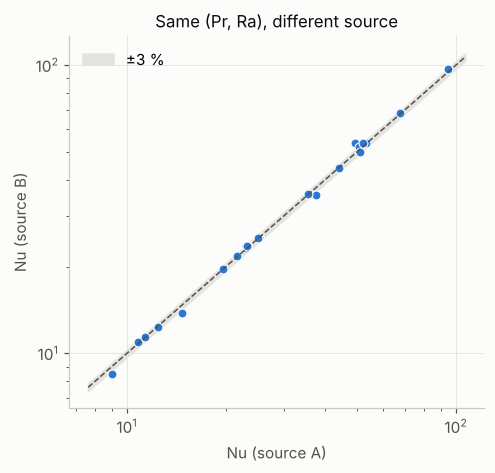

In [9]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
pairs = [(a, b) for _, d in rep.groupby("group") for a, b in itertools.combinations(d.Nu.values, 2)]
pa = np.array(pairs)
ax.scatter(pa[:, 0], pa[:, 1], c=SER[0], **DOT)
lim = [pa.min() * 0.9, pa.max() * 1.1]
ax.plot(lim, lim, color=INK2, lw=1, ls="--"); ax.fill_between(lim, np.array(lim) * 0.97, np.array(lim) * 1.03, color=GRID, zorder=0, label="±3 %")
ax.set(xscale="log", yscale="log", xlabel="Nu (source A)", ylabel="Nu (source B)", title="Same (Pr, Ra), different source")
ax.legend(loc="upper left"); fig.tight_layout(); save(fig, "04_cross_source_parity")

## 3. Train / validation / test split

The split is **grouped**: every row with the same `(Pr, Ra)` lands in the same
split, so duplicated points cannot leak from train into test. It is 70 / 15 / 15
by group, with a fixed seed. Hyperparameters are chosen on **validation**, and
**test** is used once, at the end of Section 4.

In [10]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trval_idx, test_idx = next(gss.split(X_all, y_all, g_all))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr_rel, va_rel = next(gss2.split(X_all[trval_idx], y_all[trval_idx], g_all[trval_idx]))
train_idx, val_idx = trval_idx[tr_rel], trval_idx[va_rel]
df["split"] = "train"; df.loc[val_idx, "split"] = "val"; df.loc[test_idx, "split"] = "test"
assert not (set(g_all[train_idx]) & set(g_all[test_idx])) and not (set(g_all[val_idx]) & set(g_all[test_idx]))

# Which val/test points lie inside the convex hull of the training inputs (interpolation)?
hull = Delaunay(X_all[train_idx])
df["inside_train_hull"] = hull.find_simplex(X_all) >= 0

split_ranges = pd.DataFrame([ranges(df[df.split == s], s) for s in ["train", "val", "test"]] + [overall])
split_ranges["inside train hull"] = [f"{df[df.split==s].inside_train_hull.mean():.0%}" for s in ["train", "val", "test"]] + ["—"]
split_ranges.to_csv(TAB / "ranges_by_split.csv")
split_ranges.style.format(fmt)

,rows,distinct points,Pr min,Pr max,Ra min,Ra max,Nu min,Nu median,Nu max,inside train hull
train,138.000000,120.000000,0.005,100,1.0e+06,1.0e+12,5.91,25.2,394,100%
val,28.000000,26.000000,0.021,50,5.0e+05,3.0e+11,5.2,26.8,262,96%
test,28.000000,26.000000,0.023,100,1.0e+07,1.0e+10,11.4,29.4,106,100%
ALL DATA,194.000000,172.000000,0.005,100,5.0e+05,1.0e+12,5.2,25.3,394,—


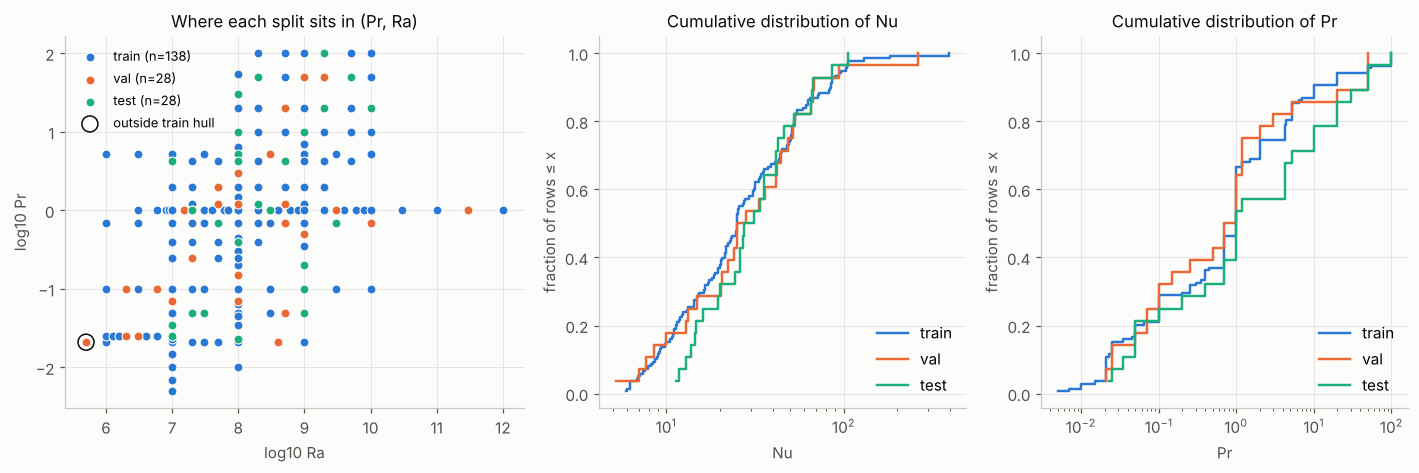

In [11]:
fig = plt.figure(figsize=(13, 4.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 1])
a0 = fig.add_subplot(gs[0])
for s in ["train", "val", "test"]:
    d = df[df.split == s]
    a0.scatter(d.logRa, d.logPr, c=SPLIT_COLOR[s], label=f"{s} (n={len(d)})", **DOT)
ext = df[(df.split != "train") & ~df.inside_train_hull]
a0.scatter(ext.logRa, ext.logPr, s=110, facecolor="none", edgecolor=INK, linewidth=1, label="outside train hull")
a0.set(xlabel="log10 Ra", ylabel="log10 Pr", title="Where each split sits in (Pr, Ra)")
a0.legend(loc="upper left", fontsize=8.5)
for k, (col, lab) in enumerate([("Nu", "Nu"), ("Pr", "Pr")]):
    a = fig.add_subplot(gs[k + 1])
    for s in ["train", "val", "test"]:
        v = np.sort(df.loc[df.split == s, col].values)
        a.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=SPLIT_COLOR[s], label=s)
    a.set(xscale="log", xlabel=lab, ylabel="fraction of rows ≤ x", title=f"Cumulative distribution of {lab}")
    a.legend(loc="lower right")
fig.tight_layout(); save(fig, "05_split_coverage")

## 4. Models

All models see `log10 Pr, log10 Ra`. The paper's methods (linear, polynomial,
SVR, random forest) predict raw `Nu`, as in Sec. 3.3. The alternatives use a
**log-`Nu` target** where it helps, because `Nu` spans two decades and errors
should be relative.

| Model | Why it is here |
|---|---|
| Multiple linear regression, polynomial (deg 2) | the paper's first attempts |
| SVR (RBF) | the paper's third attempt |
| Random forest, 5 trees | **the paper's method** |
| Random forest, 300 trees, log target | the same idea, properly sized |
| Gradient boosting, log target | stronger tree ensemble |
| Power law `Nu = C Ra^a Pr^b` | classical scaling (a log-linear model) |
| Log-quadratic | power law plus curvature in `log Pr` and a `Pr–Ra` cross term |
| Gaussian process, log target | smooth, gives an uncertainty for every prediction |
| Power law + GP residual | physics mean with GP corrections (physics-informed GP) |

In [12]:
def log_target(est):
    return TransformedTargetRegressor(regressor=est, func=np.log10, inverse_func=lambda z: 10 ** z, check_inverse=False)

def gp_kernel(kind="rbf"):
    base = {"rbf": RBF([1.0, 1.0], (1e-2, 1e2)),
            "matern15": Matern([1.0, 1.0], (1e-2, 1e2), nu=1.5),
            "matern25": Matern([1.0, 1.0], (1e-2, 1e2), nu=2.5),
            "rq": RationalQuadratic(1.0, 1.0, (1e-2, 1e2))}[kind]
    return C(1.0, (1e-3, 1e3)) * base + WhiteKernel(1e-4, (1e-8, 1e-1))

class PowerLaw(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        self.lr_ = LinearRegression().fit(X, np.log10(y)); return self
    def predict(self, X): return 10 ** self.lr_.predict(X)
    def formula(self):
        b, a = self.lr_.coef_
        return f"Nu = {10**self.lr_.intercept_:.4f} · Ra^{a:.3f} · Pr^{b:.3f}"

class PowerLawGP(BaseEstimator, RegressorMixin):
    # log10 Nu = power-law mean + GP(residual)
    def __init__(self, kind="rbf"): self.kind = kind
    def fit(self, X, y):
        z = np.log10(y)
        self.lr_ = LinearRegression().fit(X, z)
        self.sc_ = StandardScaler().fit(X)
        self.gp_ = GaussianProcessRegressor(gp_kernel(self.kind), normalize_y=True, random_state=0)
        self.gp_.fit(self.sc_.transform(X), z - self.lr_.predict(X)); return self
    def predict(self, X, return_std=False):
        m, s = self.gp_.predict(self.sc_.transform(X), return_std=True)
        z = self.lr_.predict(X) + m
        return (10 ** z, s) if return_std else 10 ** z

def make_gp(kind="rbf"):
    return log_target(make_pipeline(StandardScaler(), GaussianProcessRegressor(gp_kernel(kind), normalize_y=True, random_state=0)))

BASELINE = "Random forest, 5 trees (paper)"
MODELS = {
    "Multiple linear regression": lambda **p: LinearRegression(),
    "Polynomial regression (deg 2)": lambda **p: make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "SVR (RBF)": lambda C_=100, eps=0.5, gamma="scale": make_pipeline(StandardScaler(), SVR(C=C_, epsilon=eps, gamma=gamma)),
    BASELINE: lambda **p: RandomForestRegressor(n_estimators=5, random_state=SEED),
    "Random forest, 300 trees (log)": lambda leaf=1, depth=None: log_target(RandomForestRegressor(300, min_samples_leaf=leaf, max_depth=depth, random_state=SEED, n_jobs=-1)),
    "Gradient boosting (log)": lambda n=300, lr=0.05, depth=3: log_target(GradientBoostingRegressor(n_estimators=n, learning_rate=lr, max_depth=depth, random_state=SEED)),
    "Power law": lambda **p: PowerLaw(),
    "Log-quadratic": lambda **p: log_target(make_pipeline(PolynomialFeatures(2), LinearRegression())),
    "Gaussian process (log)": lambda kind="rbf": make_gp(kind),
    "Power law + GP residual": lambda kind="rbf": PowerLawGP(kind),
}
GRIDS = {   # tuned on the validation split only
    "SVR (RBF)": [dict(C_=c, eps=e, gamma=g) for c in (10, 100, 1000) for e in (0.1, 0.5, 1.0) for g in ("scale", 0.5, 2.0)],
    "Random forest, 300 trees (log)": [dict(leaf=l, depth=d) for l in (1, 2, 4) for d in (None, 6, 10)],
    "Gradient boosting (log)": [dict(n=n, lr=r, depth=d) for n in (150, 300, 600) for r in (0.03, 0.1) for d in (2, 3, 4)],
    "Gaussian process (log)": [dict(kind=k) for k in ("rbf", "matern15", "matern25", "rq")],
    "Power law + GP residual": [dict(kind=k) for k in ("rbf", "matern15", "matern25", "rq")],
}

def metrics(y, p):
    rel = np.abs(p / y - 1)
    return {"MAPE %": 100 * rel.mean(), "max err %": 100 * rel.max(), "R2": r2_score(y, p),
            "RMSE log10": np.sqrt(np.mean((np.log10(np.clip(p, 1e-6, None)) - np.log10(y)) ** 2))}

### 4a. Tune on validation, then evaluate on test (once)

In [13]:
Xtr, ytr = X_all[train_idx], y_all[train_idx]
Xva, yva = X_all[val_idx], y_all[val_idx]
Xte, yte = X_all[test_idx], y_all[test_idx]
Xtv, ytv = X_all[trval_idx], y_all[trval_idx]

BEST = {}
tune_log = []
for name, ctor in MODELS.items():
    best = (np.inf, {})
    for params in GRIDS.get(name, [{}]):
        p = ctor(**params).fit(Xtr, ytr).predict(Xva)
        score = metrics(yva, p)["MAPE %"]
        tune_log.append({"model": name, "params": params, "val MAPE %": score})
        if score < best[0]: best = (score, params)
    BEST[name] = best[1]
    print(f"{name:34s} val MAPE {best[0]:6.2f} %   {best[1]}")
pd.DataFrame(tune_log).to_csv(TAB / "tuning_log.csv", index=False)

Multiple linear regression         val MAPE  91.36 %   {}
Polynomial regression (deg 2)      val MAPE  39.56 %   {}


SVR (RBF)                          val MAPE   2.91 %   {'C_': 1000, 'eps': 0.1, 'gamma': 0.5}
Random forest, 5 trees (paper)     val MAPE   5.89 %   {}


Random forest, 300 trees (log)     val MAPE   6.24 %   {'leaf': 1, 'depth': 10}


Gradient boosting (log)            val MAPE   4.20 %   {'n': 600, 'lr': 0.1, 'depth': 3}
Power law                          val MAPE   5.10 %   {}
Log-quadratic                      val MAPE   3.69 %   {}


Gaussian process (log)             val MAPE   1.54 %   {'kind': 'matern15'}


Power law + GP residual            val MAPE   1.89 %   {'kind': 'matern15'}


In [14]:
test_rows, TEST_PRED = [], {}
inside = df.inside_train_hull.to_numpy()[test_idx]
for name, ctor in MODELS.items():
    m = ctor(**BEST[name]).fit(Xtv, ytv)        # refit on train + val
    p = m.predict(Xte); TEST_PRED[name] = p
    r = {"model": name, **metrics(yte, p)}
    r["MAPE % (interp.)"] = 100 * np.mean(np.abs(p[inside] / yte[inside] - 1))
    r["MAPE % (extrap.)"] = 100 * np.mean(np.abs(p[~inside] / yte[~inside] - 1)) if (~inside).any() else np.nan
    test_rows.append(r)
test_table = pd.DataFrame(test_rows).set_index("model").sort_values("MAPE %")
test_table.to_csv(TAB / "test_results.csv")
print(f"test set: {len(yte)} rows ({inside.sum()} interpolation, {(~inside).sum()} extrapolation)")
print("Power law fit on train+val:", PowerLaw().fit(Xtv, ytv).formula())
test_table.round(3)

test set: 28 rows (28 interpolation, 0 extrapolation)
Power law fit on train+val: Nu = 0.0986 · Ra^0.299 · Pr^0.031


,MAPE %,max err %,R2,RMSE log10,MAPE % (interp.),MAPE % (extrap.)
model,,,,,,
Power law + GP residual,1.005,5.678,1.000,0.006,1.005,NaN
Gaussian process (log),1.064,3.665,1.000,0.006,1.064,NaN
SVR (RBF),1.067,5.765,1.000,0.007,1.067,NaN
"Random forest, 300 trees (log)",2.308,8.954,0.998,0.014,2.308,NaN
Gradient boosting (log),2.555,8.506,0.998,0.016,2.555,NaN
"Random forest, 5 trees (paper)",2.557,8.742,0.998,0.015,2.557,NaN
Power law,3.357,9.253,0.997,0.018,3.357,NaN
Log-quadratic,3.701,9.204,0.993,0.020,3.701,NaN
Polynomial regression (deg 2),20.675,55.607,0.932,0.146,20.675,NaN


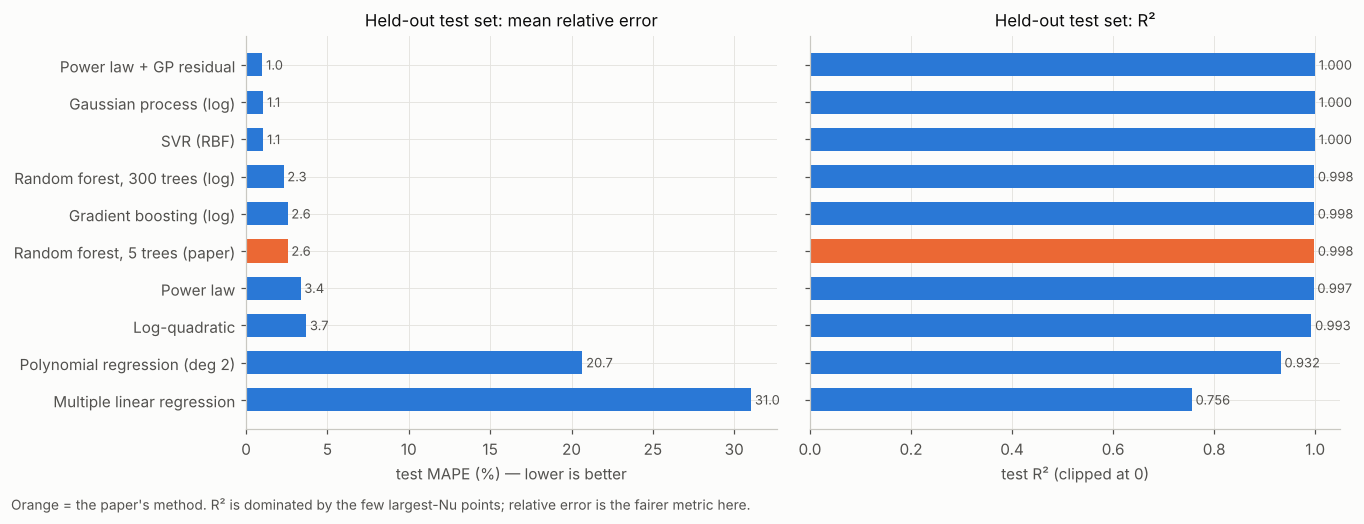

In [15]:
order = test_table.index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
cols = [SER[1] if n == BASELINE else SER[0] for n in order]
ax[0].barh(order, test_table.loc[order, "MAPE %"], color=cols, height=0.62)
ax[0].set(xlabel="test MAPE (%) — lower is better", title="Held-out test set: mean relative error")
for i, v in enumerate(test_table.loc[order, "MAPE %"]): ax[0].text(v, i, f" {v:.1f}", va="center", color=INK2, fontsize=8.5)
ax[1].barh(order, test_table.loc[order, "R2"].clip(lower=0), color=cols, height=0.62)
ax[1].set(xlabel="test R² (clipped at 0)", title="Held-out test set: R²", xlim=(0, 1.05))
for i, v in enumerate(test_table.loc[order, "R2"]): ax[1].text(max(v, 0), i, f" {v:.3f}", va="center", color=INK2, fontsize=8.5)
fig.text(0.01, -0.02, "Orange = the paper's method. R² is dominated by the few largest-Nu points; relative error is the fairer metric here.", color=INK2, fontsize=9)
fig.tight_layout(); save(fig, "06_test_results")

**Read this with care.** The test set is one random draw of about 15 % of the
points. Check the "inside train hull" column in the split table: if every test
point lies inside the training data, the test error is an *interpolation*
error and comes out optimistic. The repeated grouped CV (Section 5) and the
extrapolation tests (Section 8) are the numbers to quote.

### 4b. Parity and residuals on the test set

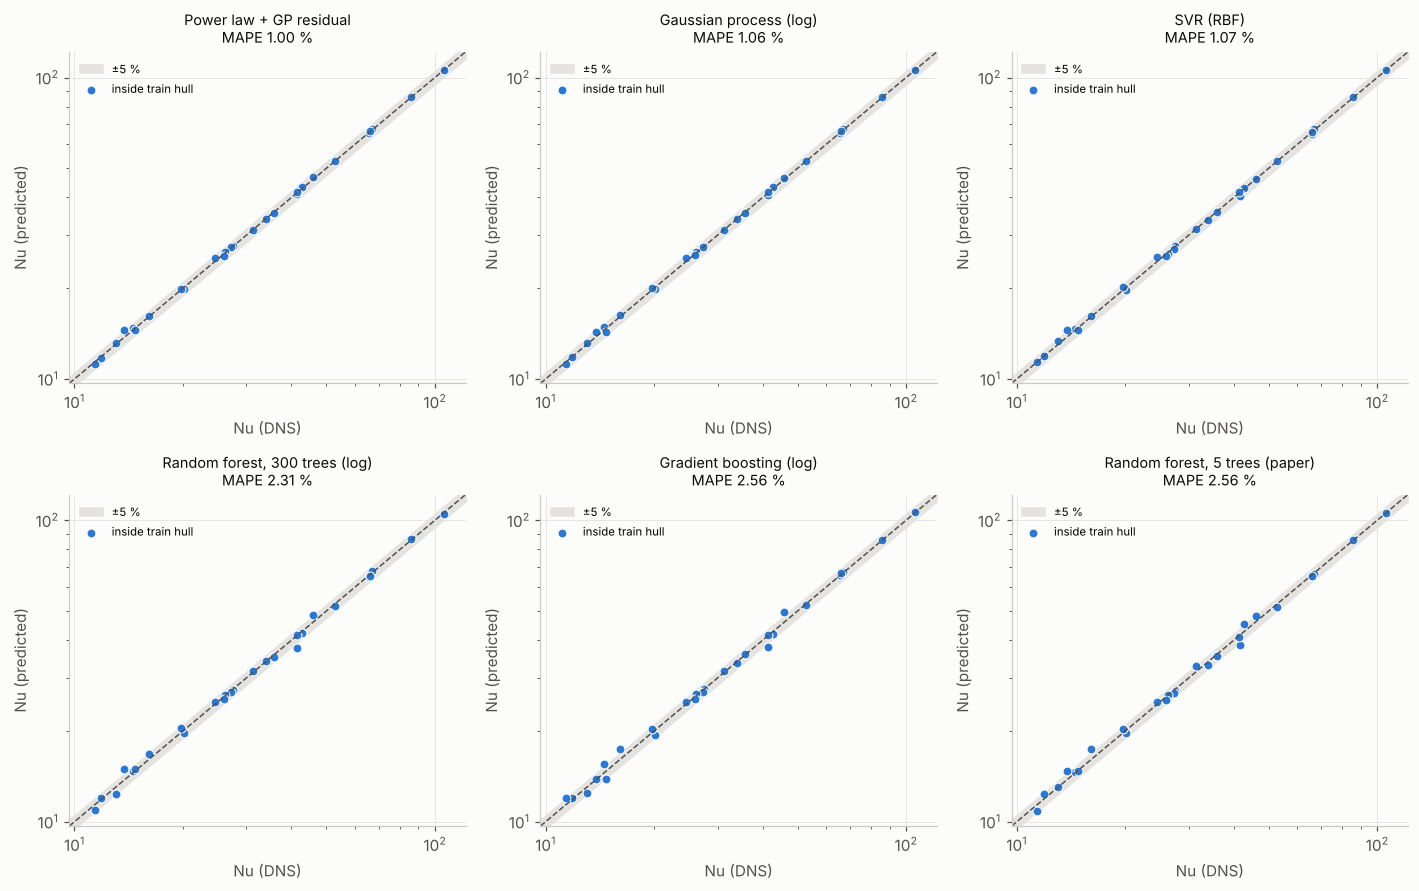

In [16]:
show = list(test_table.index[:5]) + ([BASELINE] if BASELINE not in test_table.index[:5] else [])
fig, axes = plt.subplots(2, 3, figsize=(13, 8.2))
lim = [yte.min() * 0.85, yte.max() * 1.15]
for a, name in zip(axes.flat, show):
    p = TEST_PRED[name]
    a.fill_between(lim, np.array(lim) * 0.95, np.array(lim) * 1.05, color=GRID, zorder=0, label="±5 %")
    a.plot(lim, lim, color=INK2, lw=1, ls="--")
    a.scatter(yte[inside], p[inside], c=SER[0], label="inside train hull", **DOT)
    if (~inside).any(): a.scatter(yte[~inside], p[~inside], c=SER[1], label="extrapolation", **DOT)
    a.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Nu (DNS)", ylabel="Nu (predicted)")
    a.set_title(f"{name}\nMAPE {test_table.loc[name, 'MAPE %']:.2f} %", fontsize=9.5)
    a.legend(loc="upper left", fontsize=7.5)
for a in axes.flat[len(show):]: a.axis("off")
fig.tight_layout(); save(fig, "07_test_parity")

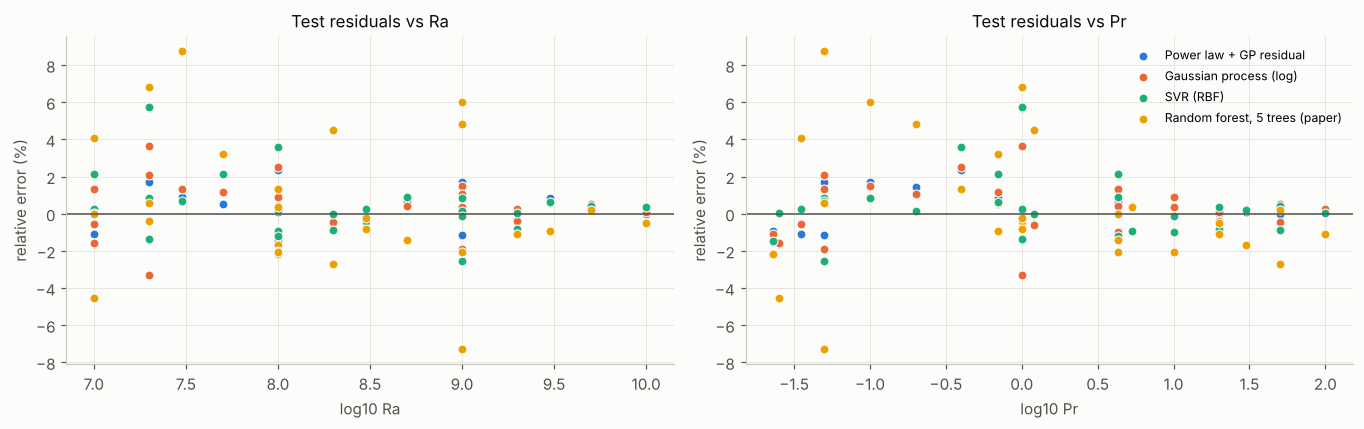

In [17]:
top3 = list(test_table.index[:3])
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
for k, name in enumerate(top3 + [BASELINE] if BASELINE not in top3 else top3):
    rel = 100 * (TEST_PRED[name] / yte - 1)
    ax[0].scatter(X_all[test_idx, 1], rel, c=SER[k], label=name, **DOT)
    ax[1].scatter(X_all[test_idx, 0], rel, c=SER[k], label=name, **DOT)
for a, lab in zip(ax, ["log10 Ra", "log10 Pr"]):
    a.axhline(0, color=INK2, lw=1); a.set(xlabel=lab, ylabel="relative error (%)")
ax[0].set_title("Test residuals vs Ra"); ax[1].set_title("Test residuals vs Pr"); ax[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "08_test_residuals")

## 5. Repeated grouped cross-validation (all data)

A single test split of about 30 rows is noisy, so this repeats a 5-fold
**grouped** CV 10 times with different group shuffles, giving 50 scores per
model. It uses the hyperparameters tuned above.

In [18]:
N_REPEATS = 10
cv_rows = []
t0 = time.time()
for rep_i in range(N_REPEATS):
    rng = np.random.default_rng(rep_i)
    ug = np.unique(g_all); perm = dict(zip(ug, rng.permutation(len(ug))))
    gperm = np.array([perm[g] for g in g_all])
    for fold, (tr, te) in enumerate(GroupKFold(5).split(X_all, y_all, gperm)):
        for name, ctor in MODELS.items():
            p = ctor(**BEST[name]).fit(X_all[tr], y_all[tr]).predict(X_all[te])
            cv_rows.append({"model": name, "repeat": rep_i, "fold": fold, **metrics(y_all[te], p)})
cv = pd.DataFrame(cv_rows); cv.to_csv(TAB / "cv_scores.csv", index=False)
cv_summary = cv.groupby("model")[["MAPE %", "max err %", "R2", "RMSE log10"]].agg(["mean", "std"]).sort_values(("MAPE %", "mean"))
cv_summary.to_csv(TAB / "cv_summary.csv")
print(f"{len(cv)//len(MODELS)} train/test splits per model, {time.time()-t0:.0f}s")
cv_summary.round(3)

50 train/test splits per model, 51s


MAPE %         max err %              R2        RMSE log10       
                                  mean     std      mean      std   mean    std       mean    std
model                                                                                            
Power law + GP residual          1.786   0.438    10.791    3.929  0.999  0.001      0.013  0.004
Gaussian process (log)           1.932   0.605    13.581    7.031  0.994  0.017      0.015  0.007
SVR (RBF)                        3.850   2.199    44.975   41.028  0.972  0.070      0.037  0.022
Gradient boosting (log)          4.409   1.084    30.500   12.547  0.920  0.087      0.034  0.014
Log-quadratic                    5.266   1.156    33.736   13.752  0.993  0.005      0.034  0.009
Power law                        5.587   1.228    35.518   13.176  0.996  0.003      0.036  0.009
Random forest, 300 trees (log)   5.611   1.468    33.015   12.438  0.924  0.115      0.043  0.018
Random forest, 5 trees (paper)   6.038   1.567    33.529   12.619  0.918  0.113      0.045  0.018
Polynomial regression (deg 2)   33.719  13.884   296.880  179.763  0.895  0.054      0.185  0.060
Multiple linear regression      67.419  23.798   534.160  203.103  0.643  0.133      2.273  0.650

/tmp/ipykernel_24869/440860025.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=True,
/tmp/ipykernel_24869/440860025.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=True,


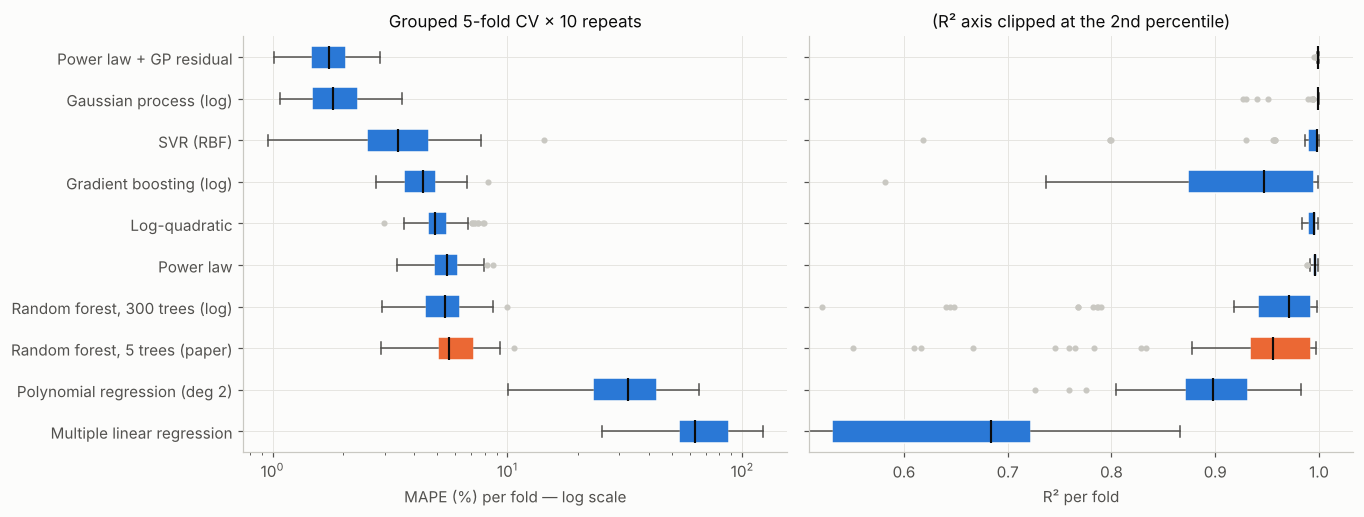

In [19]:
order = cv_summary.index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
for a, met, lab in [(ax[0], "MAPE %", "MAPE (%) per fold"), (ax[1], "R2", "R² per fold")]:
    data = [cv.loc[cv.model == n, met].values for n in order]
    bp = a.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=True,
                   medianprops=dict(color=INK, lw=1.4), whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                   flierprops=dict(marker="o", markersize=3, markerfacecolor=GHOST, markeredgecolor=GHOST))
    for patch, n in zip(bp["boxes"], order):
        patch.set_facecolor(SER[1] if n == BASELINE else SER[0]); patch.set_edgecolor(SURF)
    a.set_xlabel(lab)
ax[0].set_xscale("log"); ax[0].set_xlabel("MAPE (%) per fold — log scale")
ax[0].set_yticks(range(1, len(order) + 1), order)
ax[1].set_xlim(left=max(-0.5, cv.R2.quantile(0.02)))
ax[0].set_title("Grouped 5-fold CV × 10 repeats"); ax[1].set_title("(R² axis clipped at the 2nd percentile)")
fig.tight_layout(); save(fig, "09_cv_boxplots")

## 6. Learning curves

How does test error fall as the training set grows? For each training fraction,
a random subset of the training **groups** is drawn 15 times. The model is fitted
on that subset and scored on the fixed test set. If a curve is still falling at
100 %, more data would still help that method.

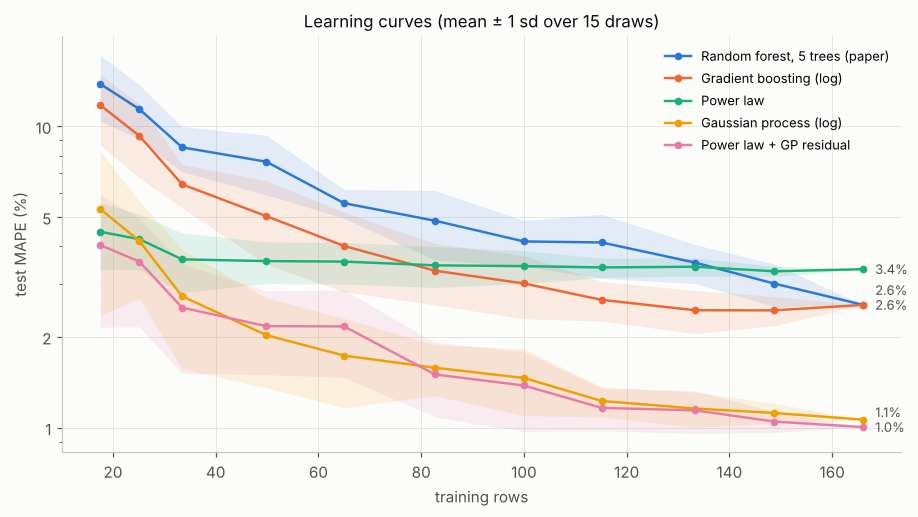

In [20]:
LC_MODELS = [BASELINE, "Gradient boosting (log)", "Power law", "Gaussian process (log)", "Power law + GP residual"]
fracs = [0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
tr_groups = np.unique(g_all[trval_idx])
lc_rows = []
for f in fracs:
    for r in range(15 if f < 1 else 1):
        rng = np.random.default_rng(1000 + r)
        pick = set(rng.choice(tr_groups, max(4, int(round(f * len(tr_groups)))), replace=False))
        idx = trval_idx[np.isin(g_all[trval_idx], list(pick))]
        for name in LC_MODELS:
            p = MODELS[name](**BEST[name]).fit(X_all[idx], y_all[idx]).predict(Xte)
            lc_rows.append({"model": name, "frac": f, "n_train": len(idx), **metrics(yte, p)})
lc = pd.DataFrame(lc_rows); lc.to_csv(TAB / "learning_curves.csv", index=False)
lcs = lc.groupby(["model", "frac"]).agg(n=("n_train", "mean"), m=("MAPE %", "mean"), s=("MAPE %", "std")).reset_index()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for k, name in enumerate(LC_MODELS):
    d = lcs[lcs.model == name]
    ax.plot(d.n, d.m, color=SER[k], marker="o", ms=4, label=name)
    ax.fill_between(d.n, d.m - d.s.fillna(0), d.m + d.s.fillna(0), color=SER[k], alpha=0.12, lw=0)
ends = lcs[lcs.frac == 1.0].set_index("model").loc[LC_MODELS, "m"]
ypos, last = {}, None
for name, v in ends.sort_values().items():          # dodge overlapping end labels (log spacing)
    y = v if last is None else max(v, last * 1.12); ypos[name] = y; last = y
for name in LC_MODELS:
    ax.annotate(f"{ends[name]:.1f}%", (lcs.n.max(), ypos[name]), xytext=(8, 0), textcoords="offset points", color=INK2, fontsize=8.5, va="center")
ax.set(xlabel="training rows", ylabel="test MAPE (%)", yscale="log", title="Learning curves (mean ± 1 sd over 15 draws)")
from matplotlib.ticker import FuncFormatter, LogLocator
ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5))); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.legend(fontsize=8.5); fig.tight_layout(); save(fig, "10_learning_curves")

## 7. Active learning curves

**Question.** If we could choose which `(Pr, Ra)` to simulate next, how many DNS
runs would we need to reach a given accuracy, compared with picking at random?

**Setup.** 20 % of the `(Pr, Ra)` groups are held out as a test set and the
rest form the pool ("simulations we could run"). Each run starts from 8 random
labelled points, then queries 2 points per round. After every round a Gaussian
process (log target) is refitted and scored on the test set by **mean** and
**worst-case** relative error. Active learning aims to fix the poorly sampled
regions, so the worst case is where it should show. To avoid depending on one
lucky test set, everything is repeated over **5 different test splits × 4
random starts = 20 runs per strategy**. Bands are 95 % confidence intervals of
the mean.

| Strategy | Picks the pool point with… |
|---|---|
| Random | — (baseline) |
| GP uncertainty | the largest GP predictive standard deviation |
| RF disagreement | the largest spread between the trees of a 100-tree forest (query-by-committee) |
| Space-filling | the largest distance in `(log Pr, log Ra)` to anything already labelled |

The learner is the same GP for all four, so the curves compare **which points**
get chosen, not which model is used.

In [21]:
AL_SPLITS, AL_SEEDS, AL_INIT, AL_BATCH = 5, 4, 8, 2
sc_al = StandardScaler().fit(X_all)
GP_KIND = BEST["Gaussian process (log)"].get("kind", "rbf")

def fit_gp_log(idx):
    gp = GaussianProcessRegressor(gp_kernel(GP_KIND), normalize_y=True, random_state=0)
    return gp.fit(sc_al.transform(X_all[idx]), np.log10(y_all[idx]))

def score(gp, te):
    rel = np.abs(10 ** gp.predict(sc_al.transform(X_all[te])) / y_all[te] - 1)
    return 100 * rel.mean(), 100 * rel.max()

def choose(strategy, lab, pool, gp, rng):
    if strategy == "Random":
        return rng.choice(pool, AL_BATCH, replace=False)
    if strategy == "GP uncertainty":
        _, s = gp.predict(sc_al.transform(X_all[pool]), return_std=True)
        return pool[np.argsort(-s)[:AL_BATCH]]
    if strategy == "RF disagreement":
        rf = RandomForestRegressor(100, random_state=int(rng.integers(1e6)), n_jobs=-1).fit(X_all[lab], np.log10(y_all[lab]))
        spread = np.stack([t.predict(X_all[pool]) for t in rf.estimators_]).std(0)
        return pool[np.argsort(-spread)[:AL_BATCH]]
    if strategy == "Space-filling":
        picked, labs = [], list(lab)
        for _ in range(AL_BATCH):
            cand = np.setdiff1d(pool, picked)
            d = np.min(np.linalg.norm(sc_al.transform(X_all[cand])[:, None] - sc_al.transform(X_all[labs])[None], axis=2), axis=1)
            j = cand[np.argmax(d)]; picked.append(j); labs.append(j)
        return np.array(picked)

STRATS = ["Random", "GP uncertainty", "RF disagreement", "Space-filling"]
al_rows, QUERY_ORDER = [], {}
t0 = time.time()
for o in range(AL_SPLITS):
    pool_all, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=100 + o).split(X_all, y_all, g_all))
    for strat in STRATS:
        for s in range(AL_SEEDS):
            rng = np.random.default_rng(1000 * o + s)
            lab = rng.choice(pool_all, AL_INIT, replace=False)
            pool = np.setdiff1d(pool_all, lab)
            order_log = list(lab)
            while True:
                gp = fit_gp_log(lab)
                mape, mx = score(gp, te)
                al_rows.append({"split": o, "strategy": strat, "seed": s, "n_labelled": len(lab), "MAPE %": mape, "max err %": mx})
                if len(pool) < AL_BATCH: break
                q = choose(strat, lab, pool, gp, rng)
                lab = np.concatenate([lab, q]); pool = np.setdiff1d(pool, q); order_log += list(q)
            if o == 0 and s == 0: QUERY_ORDER[strat] = order_log
    print(f"test split {o + 1}/{AL_SPLITS} done ({time.time() - t0:.0f}s)")
al = pd.DataFrame(al_rows); al.to_csv(TAB / "active_learning_curves.csv", index=False)
POOL_SIZE = int(al.groupby(["split"]).n_labelled.max().min())

test split 1/5 done (86s)


test split 2/5 done (177s)


test split 3/5 done (268s)


test split 4/5 done (362s)


test split 5/5 done (449s)


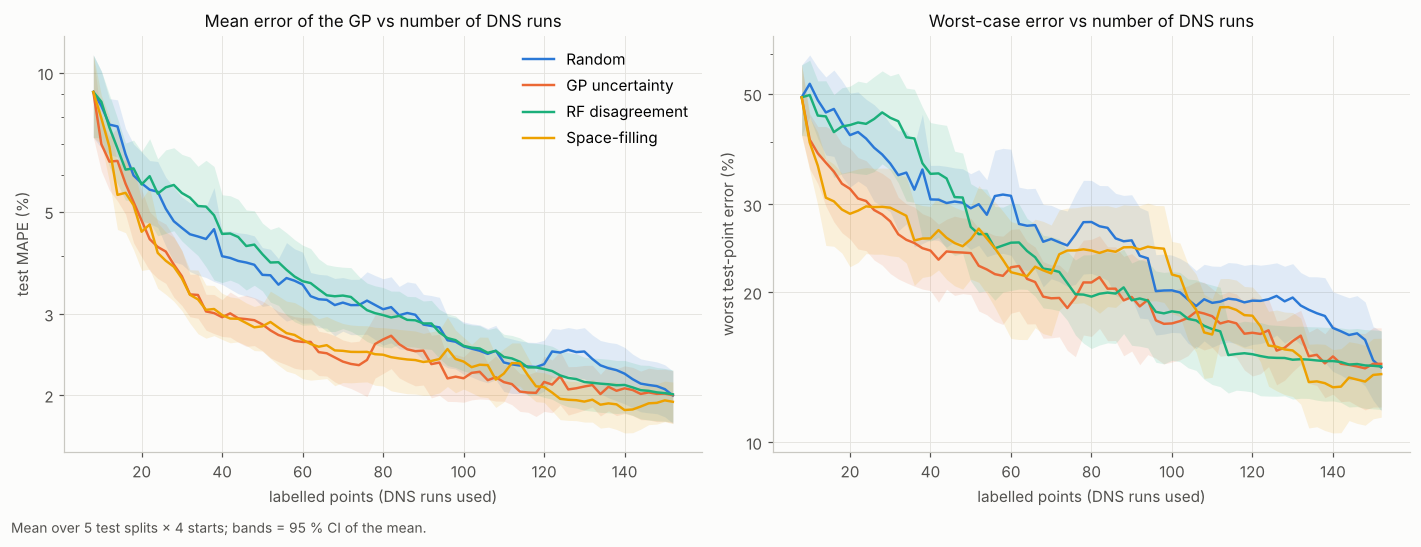

In [22]:
nmax = al.groupby(["split", "strategy", "seed"]).n_labelled.max().min()     # common range over splits
alc = al[al.n_labelled <= nmax]
als = alc.groupby(["strategy", "n_labelled"]).agg(
    m=("MAPE %", "mean"), ms=("MAPE %", "std"), x=("max err %", "mean"), xs=("max err %", "std"), n=("MAPE %", "size")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for k, strat in enumerate(STRATS):
    d = als[als.strategy == strat]
    for a, mc, sc_ in [(ax[0], "m", "ms"), (ax[1], "x", "xs")]:
        ci = 1.96 * d[sc_] / np.sqrt(d.n)
        a.plot(d.n_labelled, d[mc], color=SER[k], label=strat)
        a.fill_between(d.n_labelled, d[mc] - ci, d[mc] + ci, color=SER[k], alpha=0.13, lw=0)
ax[0].set(yscale="log", xlabel="labelled points (DNS runs used)", ylabel="test MAPE (%)", title="Mean error of the GP vs number of DNS runs")
ax[1].set(yscale="log", xlabel="labelled points (DNS runs used)", ylabel="worst test-point error (%)", title="Worst-case error vs number of DNS runs")
from matplotlib.ticker import FuncFormatter, LogLocator
for a in ax:
    a.yaxis.set_major_locator(LogLocator(subs=(1, 2, 3, 5)))
    a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    a.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax[0].legend(); fig.text(0.01, -0.02, f"Mean over {AL_SPLITS} test splits × {AL_SEEDS} starts; bands = 95 % CI of the mean.", color=INK2, fontsize=9)
fig.tight_layout(); save(fig, "11_active_learning_curves")

In [23]:
# DNS runs needed to reach a target accuracy: median over the runs that reach it,
# and how many of the 20 runs reach it at all (so no run silently drops out)
def labels_needed(strat, col, target):
    out = []
    for (o, sd), d in al[al.strategy == strat].groupby(["split", "seed"]):
        hit = d[d[col] <= target]
        out.append(hit.n_labelled.min() if len(hit) else np.nan)
    out = np.array(out, float)
    k = int(np.isfinite(out).sum())
    return f"{np.nanmedian(out):.0f}  ({k}/{len(out)})" if k else f"never (0/{len(out)})"

need = pd.DataFrame({**{f"mean ≤ {t}%": [labels_needed(s, "MAPE %", t) for s in STRATS] for t in (4, 3, 2.5)},
                     **{f"worst ≤ {t}%": [labels_needed(s, "max err %", t) for s in STRATS] for t in (25, 15)}},
                    index=STRATS)
need["pool size"] = POOL_SIZE
need.to_csv(TAB / "active_learning_labels_needed.csv")
print("DNS runs needed to reach each test accuracy: median (runs that reached it / all runs)")
need

DNS runs needed to reach each test accuracy: median (runs that reached it / all runs)


,mean ≤ 4%,mean ≤ 3%,mean ≤ 2.5%,worst ≤ 25%,worst ≤ 15%,pool size
Random,34 (20/20),50 (19/20),82 (18/20),40 (20/20),89 (16/20),152
GP uncertainty,22 (20/20),37 (20/20),48 (20/20),32 (20/20),46 (16/20),152
RF disagreement,34 (20/20),44 (18/20),76 (17/20),38 (20/20),72 (17/20),152
Space-filling,18 (20/20),32 (20/20),48 (20/20),29 (20/20),45 (16/20),152


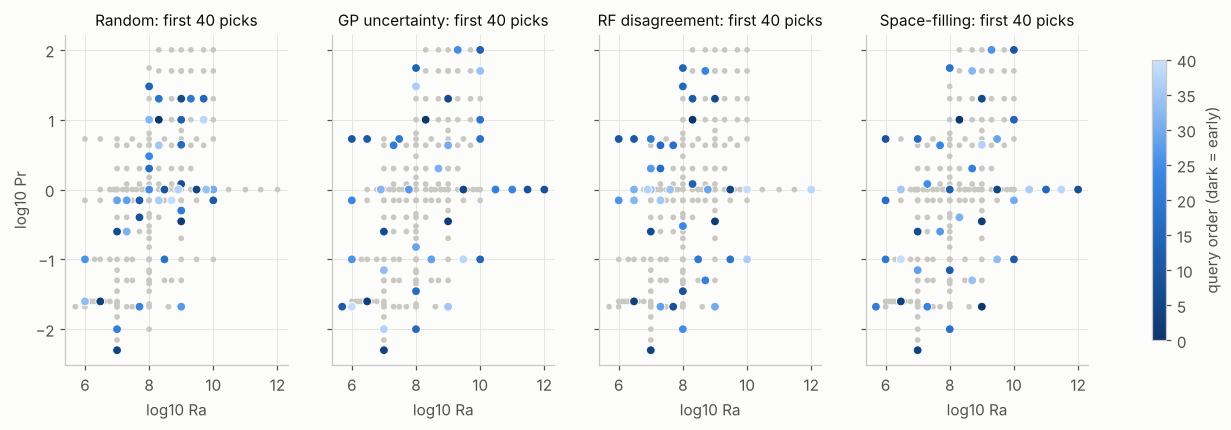

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharex=True, sharey=True)
for a, strat in zip(axes, STRATS):
    order_log = QUERY_ORDER[strat]
    rank = np.full(len(df), np.nan); rank[order_log] = np.arange(len(order_log))
    a.scatter(df.logRa, df.logPr, c=GHOST, s=14, edgecolor="none")
    first = np.array(order_log[:40])
    sc = a.scatter(df.logRa.values[first], df.logPr.values[first], c=rank[first], cmap=BLUES.reversed(), vmin=0, vmax=40, **DOT)
    a.set_title(f"{strat}: first 40 picks", fontsize=10); a.set_xlabel("log10 Ra")
axes[0].set_ylabel("log10 Pr")
fig.colorbar(sc, ax=axes, label="query order (dark = early)", shrink=0.85)
save(fig, "12_active_learning_query_maps")

## 8. Extrapolation stress tests

How far can each model be trusted outside the data it saw? Each test trains on
one region and predicts another.

In [25]:
TESTS = {
    "hold out Ra > 1e9":           df.Ra > 1e9,
    "hold out Pr < 0.02":          df.Pr < 0.02,
    "hold out Pr > 10":            df.Pr > 10,
    "hold out He 2021 (largest source)": df.Source == "He2021_Fig5a_vector",
    "hold out Zhou group":         df.Family == "Zhou group (compact FD)",
    "hold out van der Poel group": df.Family == "van der Poel group (FD)",
    "hold out Pandey group":       df.Family == "Pandey group (spectral element)",
}
ext_rows = []
for tname, mask in TESTS.items():
    m = mask.to_numpy()
    for name, ctor in MODELS.items():
        p = ctor(**BEST[name]).fit(X_all[~m], y_all[~m]).predict(X_all[m])
        ext_rows.append({"test": f"{tname} (n={m.sum()})", "model": name, "MAPE %": metrics(y_all[m], p)["MAPE %"]})
ext = pd.DataFrame(ext_rows).pivot(index="model", columns="test", values="MAPE %")
ext = ext.loc[cv_summary.index]
ext.to_csv(TAB / "extrapolation_tests.csv")
ext.round(2)

test,hold out He 2021 (largest source) (n=62),hold out Pandey group (n=59),hold out Pr < 0.02 (n=5),hold out Pr > 10 (n=23),hold out Ra > 1e9 (n=33),hold out Zhou group (n=33),hold out van der Poel group (n=32)
model,,,,,,,
Power law + GP residual,1.94,3.90,10.64,2.58,2.10,3.98,1.63
Gaussian process (log),3.42,4.81,2.01,3.21,10.17,3.58,1.72
SVR (RBF),3.33,8.45,15.41,10.71,25.61,18.47,2.34
Gradient boosting (log),2.80,10.61,12.40,1.51,39.21,5.09,3.42
Log-quadratic,5.53,6.85,12.53,6.67,9.53,7.13,5.12
Power law,2.99,8.36,12.89,2.60,2.32,5.83,5.04
"Random forest, 300 trees (log)",4.28,13.48,12.96,2.45,39.29,6.27,4.31
"Random forest, 5 trees (paper)",3.26,13.75,13.19,2.74,39.25,7.44,4.18
Polynomial regression (deg 2),19.27,18.70,67.93,9.82,13.99,80.96,19.78


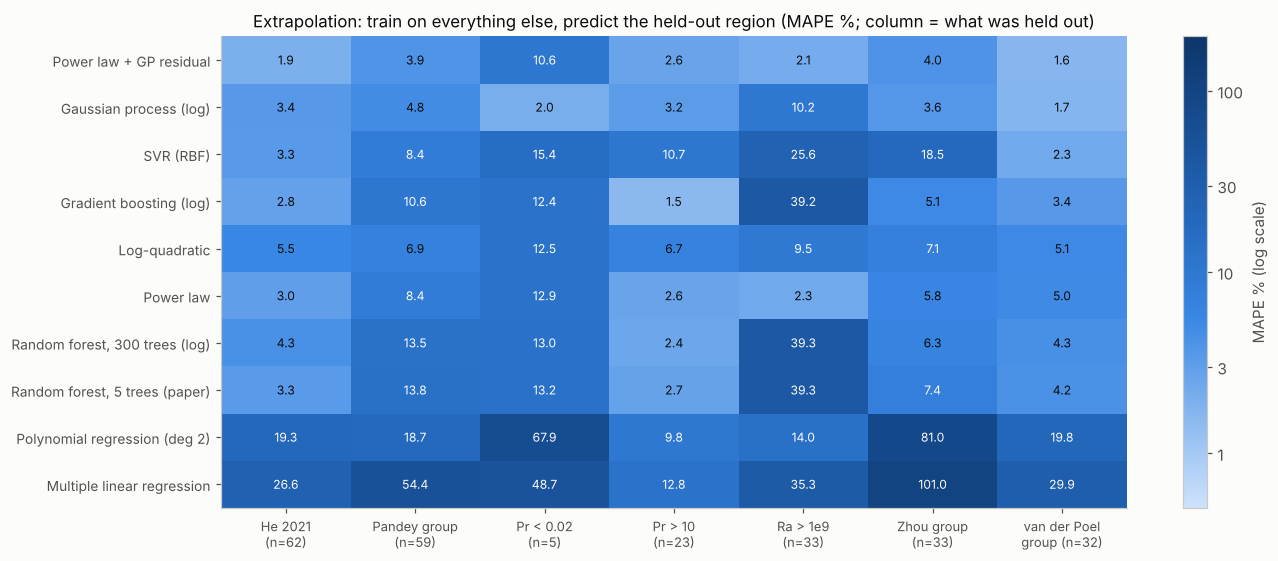

In [26]:
fig, ax = plt.subplots(figsize=(12.5, 5.2))
vals = np.log10(ext.values.clip(0.5, 200))
im = ax.imshow(vals, cmap=BLUES, aspect="auto", vmin=np.log10(0.5), vmax=np.log10(200))
import textwrap
ax.set_xticks(range(ext.shape[1]), ["\n".join(textwrap.wrap(c.replace("hold out ", "").replace(" (largest source)", ""), 13)) for c in ext.columns], fontsize=8.5)
ax.set_yticks(range(ext.shape[0]), ext.index, fontsize=9); ax.grid(False)
for i in range(ext.shape[0]):
    for j in range(ext.shape[1]):
        v = ext.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color=SURF if vals[i, j] > 0.85 else INK)
cb = fig.colorbar(im, ax=ax, label="MAPE % (log scale)")
cb.set_ticks(np.log10([1, 3, 10, 30, 100])); cb.set_ticklabels(["1", "3", "10", "30", "100"])
ax.set_title("Extrapolation: train on everything else, predict the held-out region (MAPE %; column = what was held out)")
fig.tight_layout(); save(fig, "13_extrapolation_heatmap")

## 9. Response surface of the Gaussian process

The GP is fitted on all data (log target, tuned kernel). Left: the predicted
compensated `Nu/Ra^0.3` with the data overlaid. Right: the GP's own uncertainty,
which is large exactly where there is no data. The dashed orange line marks
10 % uncertainty: inside it the surface is backed by data, outside it is
extrapolation. This uncertainty is what the active learner uses to decide where
to simulate next.

In the slices below, the dip at `Pr = 1, Ra = 1e7` is real. Those runs are in
the steady (non-turbulent) state described by Pandey & Sreenivasan (2025), with
lower `Nu`, and the GP follows them.

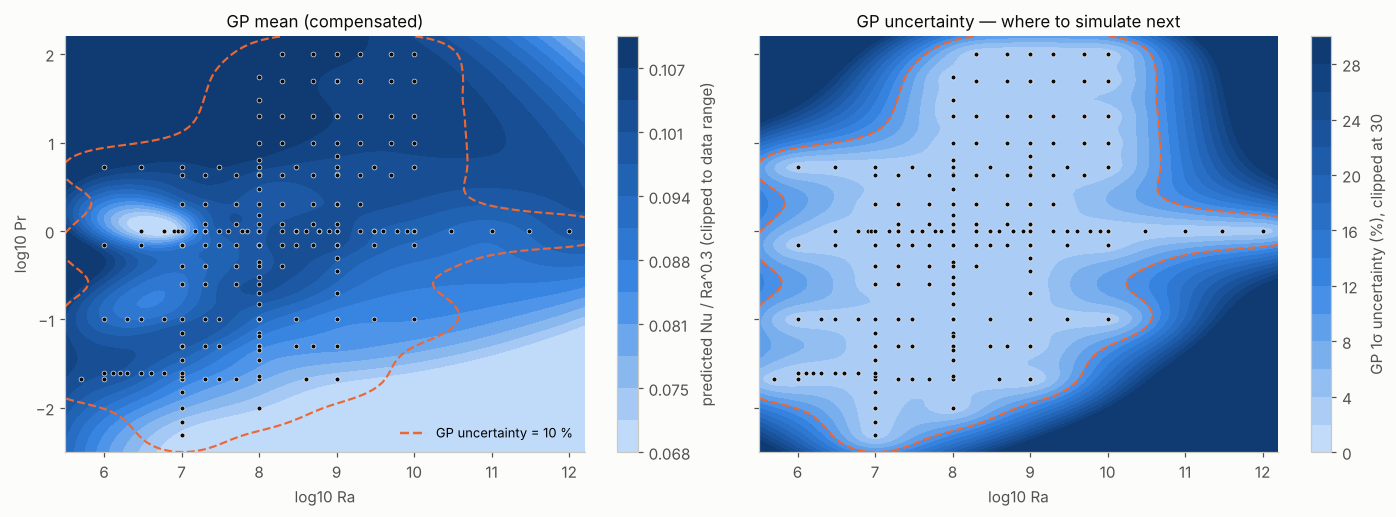

In [27]:
gp_all = MODELS["Gaussian process (log)"](**BEST["Gaussian process (log)"]).fit(X_all, y_all)
inner = gp_all.regressor_                     # pipeline(StandardScaler, GP) on log10 Nu
lp = np.linspace(df.logPr.min() - 0.2, df.logPr.max() + 0.2, 120)
lr = np.linspace(df.logRa.min() - 0.2, df.logRa.max() + 0.2, 140)
LR, LP = np.meshgrid(lr, lp)
grid = np.c_[LP.ravel(), LR.ravel()]
mu, sd = inner.predict(grid, return_std=True)
comp = (10 ** mu / 10 ** (0.3 * grid[:, 1])).reshape(LP.shape)
sdp = (100 * (10 ** sd - 1)).reshape(LP.shape)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
lo, hi = df.NuRa03.quantile(0.01), df.NuRa03.quantile(0.99)
cs = ax[0].contourf(LR, LP, np.clip(comp, lo, hi), levels=np.linspace(lo, hi, 14), cmap=BLUES)
fig.colorbar(cs, ax=ax[0], label="predicted Nu / Ra^0.3 (clipped to data range)", format="%.3f")
for a_ in ax:
    cl = a_.contour(LR, LP, sdp, levels=[10], colors=[SER[1]], linewidths=1.4, linestyles="--")
ax[0].plot([], [], color=SER[1], ls="--", label="GP uncertainty = 10 %"); ax[0].legend(loc="lower right", fontsize=8.5)
cs2 = ax[1].contourf(LR, LP, np.clip(sdp, 0, 30), levels=np.linspace(0, 30, 16), cmap=BLUES)
fig.colorbar(cs2, ax=ax[1], label="GP 1σ uncertainty (%), clipped at 30")
for a in ax:
    a.scatter(df.logRa, df.logPr, s=10, c=INK, edgecolor=SURF, linewidth=0.4)
    a.set_xlabel("log10 Ra")
ax[0].set_ylabel("log10 Pr"); ax[0].set_title("GP mean (compensated)"); ax[1].set_title("GP uncertainty — where to simulate next")
fig.tight_layout(); save(fig, "14_gp_surface")

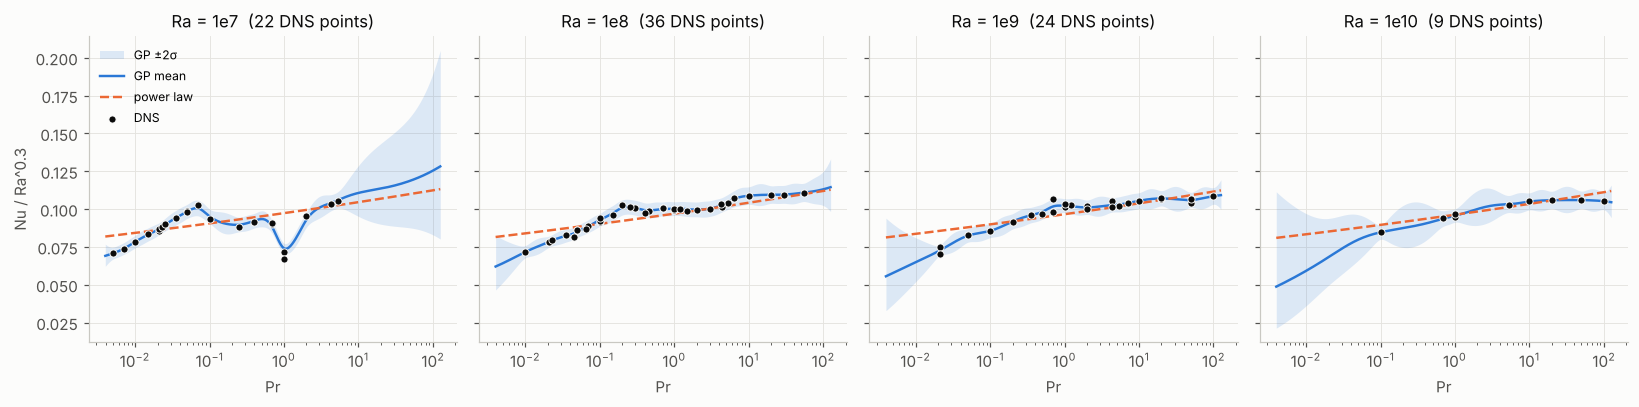

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
pgrid = np.linspace(df.logPr.min() - 0.1, df.logPr.max() + 0.1, 200)
for a, lra in zip(axes, [7, 8, 9, 10]):
    G = np.c_[pgrid, np.full_like(pgrid, lra)]
    m, s = inner.predict(G, return_std=True)
    k = 10 ** (0.3 * lra)
    a.fill_between(10 ** pgrid, 10 ** (m - 2 * s) / k, 10 ** (m + 2 * s) / k, color=SER[0], alpha=0.15, lw=0, label="GP ±2σ")
    a.plot(10 ** pgrid, 10 ** m / k, color=SER[0], label="GP mean")
    pl = PowerLaw().fit(X_all, y_all); a.plot(10 ** pgrid, pl.predict(G) / k, color=SER[1], ls="--", label="power law")
    d = df[np.isclose(df.logRa, lra)]
    a.scatter(d.Pr, d.NuRa03, c=INK, s=22, edgecolor=SURF, linewidth=0.6, zorder=3, label="DNS")
    a.set(xscale="log", xlabel="Pr", title=f"Ra = 1e{lra}  ({len(d)} DNS points)")
axes[0].set_ylabel("Nu / Ra^0.3"); axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "15_gp_slices")

## 10. Sensitivity to flagged rows

Five rows are flagged in the data: the multistable `Pr=0.7, Ra=1e9` pair, two
flow-state points from van der Poel 2012, and one conflicting low-`Pr` point
(see `docs/data_sources.pdf`, Sec. 13). This section re-runs the grouped CV
without them.

In [29]:
keep = (df.Flag == "").to_numpy()
rows = []
for rep_i in range(5):
    rng = np.random.default_rng(rep_i)
    ug = np.unique(g_all[keep]); perm = dict(zip(ug, rng.permutation(len(ug))))
    gp_ = np.array([perm[g] for g in g_all[keep]])
    Xk, yk = X_all[keep], y_all[keep]
    for tr, te in GroupKFold(5).split(Xk, yk, gp_):
        for name in cv_summary.index[:5].tolist() + [BASELINE]:
            p = MODELS[name](**BEST[name]).fit(Xk[tr], yk[tr]).predict(Xk[te])
            rows.append({"model": name, "MAPE %": metrics(yk[te], p)["MAPE %"]})
sens = pd.DataFrame(rows).groupby("model")["MAPE %"].mean().rename("MAPE % without flagged rows").to_frame()
sens["MAPE % with all rows"] = cv_summary[("MAPE %", "mean")].reindex(sens.index)
sens = sens.sort_values("MAPE % without flagged rows"); sens.to_csv(TAB / "flag_sensitivity.csv")
print(f"dropped {(~keep).sum()} flagged rows")
sens.round(3)

dropped 5 flagged rows


,MAPE % without flagged rows,MAPE % with all rows
model,,
Power law + GP residual,1.633,1.786
Gaussian process (log),1.701,1.932
SVR (RBF),3.324,3.850
Gradient boosting (log),4.307,4.409
Log-quadratic,4.902,5.266
"Random forest, 5 trees (paper)",5.756,6.038


## 11. Summary

In [30]:
best = cv_summary.index[0]
print(f"Dataset: {len(df)} rows / {df.group.nunique()} distinct points from {df.Source.nunique()} sources")
print(f"  Pr {df.Pr.min():g}–{df.Pr.max():g} | Ra {df.Ra.min():.1e}–{df.Ra.max():.1e} | Nu {df.Nu.min():g}–{df.Nu.max():g}")
print(f"  cross-source median spread at shared points: {agree.spread_pct.median():.2f} %")
print()
for s in ["train", "val", "test"]:
    d = df[df.split == s]
    print(f"{s:5s}: {len(d):3d} rows | Pr {d.Pr.min():g}–{d.Pr.max():g} | Ra {d.Ra.min():.1e}–{d.Ra.max():.1e} | Nu {d.Nu.min():g}–{d.Nu.max():g}")
print()
print(f"Best method by grouped CV: {best}  (MAPE {cv_summary.loc[best, ('MAPE %','mean')]:.2f} ± {cv_summary.loc[best, ('MAPE %','std')]:.2f} %)")
print(f"Paper's method:            {BASELINE}  (MAPE {cv_summary.loc[BASELINE, ('MAPE %','mean')]:.2f} ± {cv_summary.loc[BASELINE, ('MAPE %','std')]:.2f} %)")
print()
print("Active learning — median DNS runs needed (pool ≈ %d):" % POOL_SIZE)
print(need.drop(columns="pool size").to_string())

Dataset: 194 rows / 172 distinct points from 10 sources
  Pr 0.005–100 | Ra 5.0e+05–1.0e+12 | Nu 5.2–394.2
  cross-source median spread at shared points: 1.48 %

train: 138 rows | Pr 0.005–100 | Ra 1.0e+06–1.0e+12 | Nu 5.91–394.2
val  :  28 rows | Pr 0.021–50 | Ra 5.0e+05–3.0e+11 | Nu 5.2–262.3
test :  28 rows | Pr 0.023–100 | Ra 1.0e+07–1.0e+10 | Nu 11.38–105.85

Best method by grouped CV: Power law + GP residual  (MAPE 1.79 ± 0.44 %)
Paper's method:            Random forest, 5 trees (paper)  (MAPE 6.04 ± 1.57 %)

Active learning — median DNS runs needed (pool ≈ 152):
                   mean ≤ 4%    mean ≤ 3%  mean ≤ 2.5%  worst ≤ 25%  worst ≤ 15%
Random           34  (20/20)  50  (19/20)  82  (18/20)  40  (20/20)  89  (16/20)
GP uncertainty   22  (20/20)  37  (20/20)  48  (20/20)  32  (20/20)  46  (16/20)
RF disagreement  34  (20/20)  44  (18/20)  76  (17/20)  38  (20/20)  72  (17/20)
Space-filling    18  (20/20)  32  (20/20)  48  (20/20)  29  (20/20)  45  (16/20)


In [31]:
import zipfile
with zipfile.ZipFile(OUT / "rb_study_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in list(FIG.glob("*.png")) + list(TAB.glob("*.csv")):
        z.write(f, f.relative_to(OUT))
print("figures:", sorted(p.name for p in FIG.glob("*.png")))
print("tables:", sorted(p.name for p in TAB.glob("*.csv")))
print("zip:", OUT / "rb_study_outputs.zip")

figures: ['01_histograms.png', '02_coverage_by_family.png', '03_nu_vs_ra_pr.png', '04_cross_source_parity.png', '05_split_coverage.png', '06_test_results.png', '07_test_parity.png', '08_test_residuals.png', '09_cv_boxplots.png', '10_learning_curves.png', '11_active_learning_curves.png', '12_active_learning_query_maps.png', '13_extrapolation_heatmap.png', '14_gp_surface.png', '15_gp_slices.png']
tables: ['active_learning_curves.csv', 'active_learning_labels_needed.csv', 'cross_source_agreement.csv', 'cv_scores.csv', 'cv_summary.csv', 'extrapolation_tests.csv', 'flag_sensitivity.csv', 'learning_curves.csv', 'ranges_by_source.csv', 'ranges_by_split.csv', 'test_results.csv', 'tuning_log.csv']
zip: /tmp/claude-0/-home-claude/2b9272af-6ead-57e0-9a20-e2810656f752/scratchpad/nbrun/rb_study_outputs.zip
